<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 012 Kalibrasi Ulang dari Data Metrica</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Eksperimen 006 mengkalibrasi biaya ganti λ ke laju possession StatsBomb (1,96 per menit). Definisi StatsBomb lebih kasar daripada definisi tantangan ini, dan pada GT publik model memprediksi 11 possession untuk 17 sebenarnya, tanda kemungkinan under-segmentasi. Eksperimen ini mengganti acuan dengan **data peristiwa Metrica dari dua pertandingan lain** (Sample Game 1 dan 2, data terbuka Metrica Sports), penyedia yang sama dengan tantangan ini dan yang peristiwanya mencatat setiap umpan, bawa bola, dan perebutan.

Label per frame (H, A, D) diturunkan secara algoritmik dari peristiwa: possession berpindah ke tim yang melakukan umpan, bawa bola, tembakan, rebut, atau set piece berikutnya; bola mati dimulai pada BALL OUT, FAULT RECEIVED, kartu, atau gol dan berakhir pada peristiwa bola-hidup berikutnya. Dari label itu dihitung laju possession per menit dan dipakai sebagai target λ.

**Keterbukaan.** README tantangan memuat bahwa GT publik 5 menit memiliki 17 possession (3,4 per menit). Angka itu sudah dilihat sebelum eksperimen ini, tetapi target di sini dihitung dari pertandingan lain, dan kecocokannya dengan GT publik dicatat sebagai korobrasi, bukan dipakai menyetel.


# Metodologi

**peristiwa Metrica Sample Game 1 dan 2 → label H/A/D per frame → possession per menit dan durasi → target jumlah possession untuk 105,9 menit dinilai → λ dikalibrasi ulang pada decoder 011 (gerbang kendali 1,5 m + bukti bentuk tim TCN) → gap bola mati dari 004 → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

| asumsi | nilai | alasan |
|---|---|---|
| sumber acuan | Metrica Sports sample data, Game 1 dan 2 (penyedia sama dengan tantangan) | data pertandingan lain; peristiwa lebih halus daripada StatsBomb |
| game 3 | dikecualikan | label turunannya timpang (H 19%, A 71%), tidak dapat dipercaya |
| aturan label | possession ke tim dari umpan, bawa bola, tembakan, rebut, atau set piece terbaru; BALL LOST dan CHALLENGE tidak mengubahnya | sesuai `CHALLENGE.md`: bola lepas tetap pada tim terakhir |
| bola mati | dari BALL OUT, FAULT RECEIVED, kartu, atau gol hingga peristiwa bola-hidup berikutnya | turunan algoritmik, kasar |
| sumber data | https://github.com/metrica-sports/sample-data (harus dikreditkan di dokumen teknis) | syarat penggunaan data terbuka |

# Environment

Dijalankan dari dalam repositori. Satu-satunya akses jaringan adalah mengunduh data terbuka pertandingan **lain** (berkas publik di GitHub) ke cache `experiments/_cache/ext_metrica/` (tidak di-commit). Tidak ada data pertandingan ini yang dikirim ke mana pun.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common
import other_games as og
import possession_metrics as pm
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25
N = source_frames("tactical")
BLOCKS3 = half_video_blocks("BAR-ATH")
BL = [(a, b) for _, a, b in BLOCKS3]
GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS3: GRADED[a:b + 1] = True
GRADED_MIN = GRADED.sum() / FPS / 60
OUT = Path(common.HERE) / "012_metrica_recalibration" / "out"; OUT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
print(f"frames: {N} | dinilai: {GRADED.sum()} ({GRADED_MIN:.1f} menit)")

frames: 199319 | dinilai: 158857 (105.9 menit)


# Approach: Kalibrasi Ulang ke Laju Possession Metrica

## [1] Laju possession dari pertandingan lain

,game,menit berlabel,possession,per menit,median durasi (dtk),< 3 dtk,% D,henti permainan
0,1,96.1,322,3.35,6.4,27%,35.7%,74
1,2,94.0,295,3.14,7.5,23%,31.2%,77


laju possession Metrica: 3.25 per menit (SD diperlebar menjadi 0.30 karena hanya dua pertandingan)


pembanding StatsBomb (006): 1.96 per menit


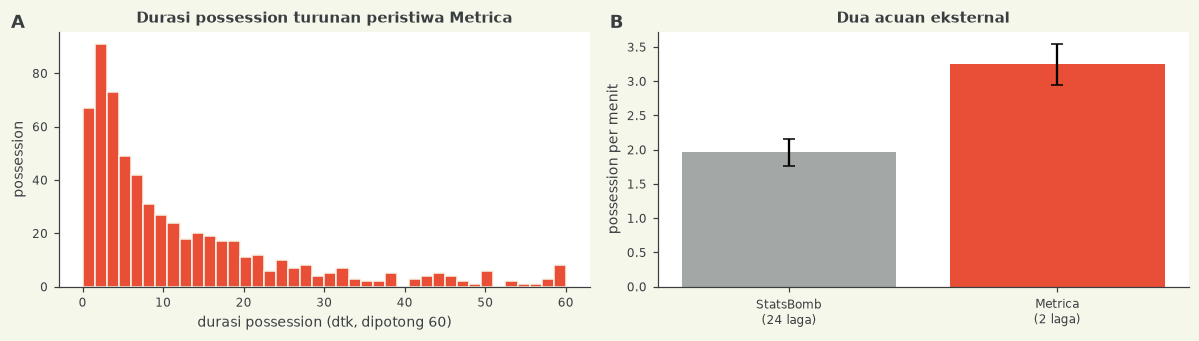

In [2]:
rows = []; DUR = []
for n in (1, 2):
    g = og.load(n); y = g["y"]; lab = y >= 0
    mins = lab.sum() / FPS / 60
    n_p = 0; dur = []
    for t in (0, 1):
        s, e = common.runs(y == t); n_p += len(s); dur += list((e - s) / FPS)
    s, e = common.runs(y == 2)
    DUR += dur
    rows.append({"game": n, "menit berlabel": round(mins, 1), "possession": n_p, "per menit": round(n_p / mins, 2),
                 "median durasi (dtk)": round(float(np.median(dur)), 1), "< 3 dtk": f"{np.mean(np.array(dur) < 3):.0%}",
                 "% D": f"{np.mean(y[lab] == 2):.1%}", "henti permainan": len(s)})
EXT = pd.DataFrame(rows); display(EXT)
RATE_M = float(EXT["per menit"].mean()); RATE_SD = max(float(EXT["per menit"].std(ddof=1)), 0.3)
print(f"laju possession Metrica: {RATE_M:.2f} per menit (SD diperlebar menjadi {RATE_SD:.2f} karena hanya dua pertandingan)")
RATE_SB, SB_SD, _ = common.external_possession_rate()
print(f"pembanding StatsBomb (006): {RATE_SB:.2f} per menit")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(np.clip(DUR, 0, 60), bins=40, color=C1, edgecolor=C3); ax[0].set(xlabel="durasi possession (dtk, dipotong 60)", ylabel="possession", title="Durasi possession turunan peristiwa Metrica")
ax[1].bar(["StatsBomb\n(24 laga)", "Metrica\n(2 laga)"], [RATE_SB, RATE_M], yerr=[SB_SD, RATE_SD], color=[GREY, C1], capsize=4); ax[1].set(ylabel="possession per menit", title="Dua acuan eksternal")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

Dua pertandingan Metrica memberi laju sekitar 3,1 sampai 3,4 per menit, jauh di atas 1,96 pada StatsBomb. Definisi StatsBomb meniadakan banyak perpindahan singkat; peristiwa Metrica mencatat tiap umpan dan perebutan sehingga possession dipecah lebih halus, dan itu lebih dekat ke definisi tantangan (run maksimal H atau A). Sekitar seperempat possession berdurasi di bawah 3 detik, seperti pada GT publik (3 dari 17).

## [2] Target jumlah possession dan kalibrasi

Target untuk 105,9 menit dinilai dihitung dari laju Metrica. Decoder sama dengan 011: gerbang kendali 1,5 m, bukti bentuk tim TCN dari 008 (κ = 0,02), gap bola mati dari 004.

In [3]:
G = common.gap_dead_ball(); DEAD = G[G.p_dead >= 0.5]
dist = common.team_distances(); dH, dA = dist[:, 0], dist[:, 1]
OBS = np.isfinite(dH) & np.isfinite(dA)
NEAR = np.where(OBS, np.minimum(dH, dA), np.inf)
E = np.zeros(N); E[OBS] = np.clip((dA[OBS] - dH[OBS]) / 3.0, -10, 10)
LPB_H, LPB_A = -np.logaddexp(0, -E), -np.logaddexp(0, E); LPB_H[~OBS] = 0; LPB_A[~OBS] = 0
P_TCN = np.load(Path(common.CACHE) / "p_tcn.npy")
pc = np.clip(P_TCN, 1e-3, 1 - 1e-3); LS_H, LS_A = np.log(pc), np.log(1 - pc)

def finish(paths):
    lab = np.full(N, "X", dtype="<U1")
    for (half, a, b), p in zip(BLOCKS3, paths):
        lab[a:b + 1] = np.where(p == 0, "H", "A")
        if half == 2: lab[a:KICKOFF2] = "D"
    for _, r in DEAD.iterrows(): lab[int(r.f0):int(r.f1)] = "D"
    return lab

def decode(r, ks, lam):
    gate = NEAR <= r
    h = np.where(gate, LPB_H, 0.0) + ks * LS_H; a = np.where(gate, LPB_A, 0.0) + ks * LS_A
    return finish([common.viterbi_2state(h[x:y + 1], a[x:y + 1], lam) for x, y in BL])

def count(lab):
    n, gaps = 0, []
    for _, a, b in BLOCKS3:
        seg = lab[a:b + 1]; st = []
        for t in ("H", "A"):
            s_, e_ = common.runs(seg == t); st += list(s_)
        st = np.sort(st); n += len(st)
        if len(st) > 1: gaps += list(np.diff(st) / FPS)
    return n, np.array(gaps)

T_MET, T_MET_SD = RATE_M * GRADED_MIN, RATE_SD * GRADED_MIN
T_SB = RATE_SB * GRADED_MIN
print(f"target Metrica: {T_MET:.0f} +/- {T_MET_SD:.0f} possession | (target StatsBomb 006: {T_SB:.0f})")

SPEC = {"gate15_tcn": (1.5, 0.02), "ungated_tcn": (np.inf, 0.02)}
LAMS = [2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200]
SWEEP = {k: [(l, count(decode(r, ks, l))[0]) for l in LAMS] for k, (r, ks) in SPEC.items()}
def solve(sw, target):
    x = np.log([l for l, _ in sw]); y = np.array([n for _, n in sw], float)
    if target >= y[0]: return float(np.exp(x[0]))
    if target <= y[-1]: return float(np.exp(x[-1]))
    return float(np.exp(np.interp(-target, -y, x)))
CAL = {}
for k in SPEC:
    CAL[k] = {"λ* (Metrica)": solve(SWEEP[k], T_MET), "λ (+1 SD)": solve(SWEEP[k], T_MET + T_MET_SD), "λ (-1 SD)": solve(SWEEP[k], max(T_MET - T_MET_SD, 1)), "λ* (StatsBomb, 006)": solve(SWEEP[k], T_SB)}
display(pd.DataFrame({k: [n for _, n in v] for k, v in SWEEP.items()}, index=[f"λ={l}" for l in LAMS]).T)
display(pd.DataFrame(CAL).T.round(1))

target Metrica: 344 +/- 32 possession | (target StatsBomb 006: 208)


,λ=2,λ=3,λ=5,λ=8,λ=12,λ=20,λ=30,λ=50,λ=80,λ=120,λ=200
gate15_tcn,480,428,361,294,248,202,172,131,117,98,84
ungated_tcn,1007,845,668,536,428,306,246,194,147,131,116


,λ* (Metrica),λ (+1 SD),λ (-1 SD),"λ* (StatsBomb, 006)"
gate15_tcn,5.6,4.5,7.1,18.7
ungated_tcn,17.1,15.0,19.5,43.6


Target Metrica mendorong λ lebih rendah daripada target StatsBomb pada kedua decoder. Pita ±1 SD memperlihatkan seberapa besar ketidakpastian dua pertandingan terhadap λ.

## [3] Varian yang dibangun

Varian utama memakai λ* Metrica pada decoder bergerbang (r = 1,5 m, ditetapkan di 011). Dua varian pita memperlihatkan sensitivitas, dan acuan 011 (λ dari StatsBomb) disertakan untuk perbandingan.

In [4]:
VARS = {"v1_metrica_gate15": ("gate15_tcn", CAL["gate15_tcn"]["λ* (Metrica)"], 1.5),
        "v2_band_lo_lambda": ("gate15_tcn", CAL["gate15_tcn"]["λ (+1 SD)"], 1.5),
        "v3_band_hi_lambda": ("gate15_tcn", CAL["gate15_tcn"]["λ (-1 SD)"], 1.5),
        "v4_metrica_ungated": ("ungated_tcn", CAL["ungated_tcn"]["λ* (Metrica)"], np.inf),
        "ref_011_statsbomb": ("gate15_tcn", CAL["gate15_tcn"]["λ* (StatsBomb, 006)"], 1.5)}
for old in OUT.glob("*.csv"): old.unlink()
LAB, rows = {}, []
for name, (key, lam, r_) in VARS.items():
    lab = decode(r_, 0.02, lam); LAB[name] = lab; write_submission(str(OUT / f"{name}.csv"), lab)
    n, g = count(lab)
    rows.append({"varian": name, "λ": round(lam, 1), "possession": n, "per menit": round(n / GRADED_MIN, 2), "median awal-ke-awal (dtk)": round(float(np.median(g)), 1),
                 "% D": round(100 * np.mean(lab[GRADED] == "D"), 1)})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS3: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, g = count(base)
rows.append({"varian": "baseline_smooth50", "λ": None, "possession": n, "per menit": round(n / GRADED_MIN, 2), "median awal-ke-awal (dtk)": round(float(np.median(g)), 1), "% D": round(100 * np.mean(base[GRADED] == "D"), 1)})
display(pd.DataFrame(rows))

,varian,λ,possession,per menit,median awal-ke-awal (dtk),% D
0,v1_metrica_gate15,5.6,341,3.22,11.7,22.7
1,v2_band_lo_lambda,4.5,375,3.54,9.6,22.7
2,v3_band_hi_lambda,7.1,303,2.86,13.3,22.7
3,v4_metrica_ungated,17.1,339,3.20,10.9,22.7
4,ref_011_statsbomb,18.7,211,1.99,22.2,22.7
5,baseline_smooth50,NaN,594,5.61,5.7,32.3


## [4] Validasi, skor, dan diagnostik (pemeriksaan pipeline)

Skor GT publik hanya memeriksa pipeline; dengan 17 possession selisih kecil adalah noise. Jumlah possession pada jendela itu dibandingkan dengan 17 sebagai korobrasi atas target eksternal, bukan sebagai dasar penyetelan.

In [5]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

gt = pm.read_label_csv(ROOT / "evaluation" / "gt" / "BAR-ATH_possession_gt_public.csv")["label"].astype(str).values
a0, b0 = 11185, 18684
GT_CH = [(i, gt[i]) for i in range(a0 + 1, b0 + 1) if gt[i] != gt[i - 1] and gt[i] in ("H", "A") and gt[i - 1] in ("H", "A")]
drows = []
for name, lab in LAB.items():
    ch = [(i, lab[i]) for i in range(a0 + 1, b0 + 1) if lab[i] != lab[i - 1] and lab[i] in ("H", "A") and lab[i - 1] in ("H", "A")]
    d = []
    for f, t in GT_CH:
        c = [(h - f) for h, u in ch if u == t and abs(h - f) <= 10 * FPS]
        if c: d.append(min(c, key=abs) / FPS)
    d = np.array(d)
    drows.append({"varian": name, "H↔A GT": len(GT_CH), "ditemukan (≤10 dtk)": len(d), "median keterlambatan (dtk)": round(float(np.median(d)), 2) if len(d) else None})
display(pd.DataFrame(drows))

baseline_smooth50.csv -> VALID


ref_011_statsbomb.csv -> VALID


v1_metrica_gate15.csv -> VALID


v2_band_lo_lambda.csv -> VALID


v3_band_hi_lambda.csv -> VALID


v4_metrica_ungated.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,ref_011_statsbomb,0.6685,0.5286,11,25.9418
1,2,v3_band_hi_lambda,0.6764,0.4933,13,21.9508
2,3,v1_metrica_gate15,0.6674,0.4500,15,19.0240
3,4,baseline_smooth50,0.6207,0.3256,26,10.8031
4,5,v2_band_lo_lambda,0.6493,0.3200,23,12.4070
5,6,v4_metrica_ungated,0.6431,0.2900,23,12.4070


,varian,H↔A GT,ditemukan (≤10 dtk),median keterlambatan (dtk)
0,v1_metrica_gate15,12,9,-1.60
1,v2_band_lo_lambda,12,10,-0.70
2,v3_band_hi_lambda,12,8,-1.48
3,v4_metrica_ungated,12,10,-1.16
4,ref_011_statsbomb,12,7,-1.60


# Ringkasan 012

**Yang dikerjakan.** Acuan eksternal λ diganti dari StatsBomb (1,96 possession per menit) ke data peristiwa Metrica dari dua pertandingan lain (Sample Game 1 dan 2, data terbuka Metrica Sports, penyedia yang sama dengan tantangan). Label H/A/D per frame diturunkan algoritmik dari peristiwa (possession ke tim dari umpan, bawa bola, tembakan, rebut, atau set piece terbaru; bola mati dari BALL OUT, FAULT RECEIVED, kartu, atau gol sampai peristiwa bola-hidup berikutnya). Game 3 dikecualikan karena label turunannya timpang (H 19%, A 71%). Decoder sama dengan 011 (gerbang kendali 1,5 m + bentuk tim TCN + gap bola mati 004); hanya λ yang dikalibrasi ulang. Semua enam berkas lolos `validate_submission.py`. Tidak ada label tangan, tidak ada GT untuk memilih target, tidak ada data tantangan yang keluar dari mesin.

**Hasil.**
1. **Dua acuan eksternal sangat berbeda.** Metrica: 3,35 dan 3,14 possession per menit (rata-rata 3,25), median durasi 6,4 sampai 7,5 detik, sekitar seperempat berdurasi di bawah 3 detik. StatsBomb: 1,96 per menit. Definisi Metrica lebih halus (mencatat tiap umpan dan perebutan) dan lebih dekat ke definisi tantangan, yaitu run maksimal H atau A.
2. **Target baru = 344 ± 32 possession** (lawan 208 sebelumnya), sehingga λ* turun dari 18,7 menjadi 5,6 (pita ±1 SD: 4,5 sampai 7,1) pada decoder bergerbang. Hasilnya 341 possession, 3,22 per menit, median awal-ke-awal 11,7 detik.
3. **Korobrasi dari GT publik (bukan dasar penyetelan).** GT publik punya 17 possession dalam 5 menit (3,4 per menit), konsisten dengan laju Metrica. Model terkalibrasi Metrica memprediksi 15 possession pada jendela itu, dibanding 11 pada varian StatsBomb. Angka 17 per 5 menit sudah terlihat di README sebelum eksperimen ini, tetapi target dihitung dari pertandingan lain.
4. **Pergantian lebih sering ditemukan:** 9 sampai 10 dari 12 pergantian H↔A GT ditemukan dalam 10 detik (7 pada varian StatsBomb), median keterlambatan −1,6 sampai −0,7 detik.

**Pemeriksaan pipeline (GT publik, 17 possession; bukan dasar pemilihan).** `ref_011_statsbomb` 0,669 macroF1 dan 0,529 spellF1; `v3_band_hi_lambda` (λ = 7,1) 0,676 dan 0,493; `v1_metrica_gate15` 0,667 dan 0,450; `baseline_smooth50` 0,621 dan 0,326. Secara jujur, spellF1 pada jendela ini **sedikit lebih menyukai** kalibrasi StatsBomb (0,529 vs 0,450), tetapi itu selisih kurang dari dua possession pada sampel 17, dalam noise, dan tidak dipakai memilih.

**Keputusan.** Calon saat ini bergeser ke `v1_metrica_gate15` karena acuannya lebih sesuai dengan definisi tantangan (penyedia sama, granularitas peristiwa lebih halus, tiga sumber independen searah: dua pertandingan Metrica dan GT publik), bukan karena skor.

**Keterbatasan.**
- Label Metrica adalah turunan kasar saya dari peristiwa: porsi bola mati 31 sampai 36% lebih tinggi daripada sekitar 20% pada GT publik, jadi aturan bola mati saya tidak sama dengan definisi GT.
- Hanya dua pertandingan (SD laju diperlebar menjadi 0,3), dan keduanya anonim sehingga kesetaraan dengan tim dan liga ini tidak diketahui.
- Kalibrasi jumlah tidak menjamin ketepatan batas. Jumlah possession penuh yang benar tetap tidak diketahui; rentang masuk akalnya 208 sampai 344 tergantung definisi, dan perbedaan itu adalah risiko terbesar saat ini.

**Langkah berikutnya.** Melatih model terawasi pada label turunan Metrica (TCN untuk tim dan bola mati) lalu mentransfernya ke pertandingan ini, yang juga memberi tanda tangan bola mati yang nyata untuk ketepatan batas.